In [1]:
# 1. Install pyspark
!pip install pyspark

# 2. Inisialisasi SparkSession
from pyspark.sql import SparkSession

# Membuat sesi Spark lokal
spark = SparkSession.builder \
    .appName("Eksplorasi-Higgs-SparkML") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

print("Apache Spark Berhasil Dijalankan!")
print(f"Versi Spark: {spark.version}")

Apache Spark Berhasil Dijalankan!
Versi Spark: 4.0.4


In [2]:
import numpy as np

# Set seed agar nilai acak konsisten
np.random.seed(42)
n_samples = 50000

# 1. Buat label biner sesuai proporsi artikel Higgs (65% kelas 0, 35% kelas 1)
labels = np.random.choice([0.0, 1.0], size=n_samples, p=[0.65, 0.35])

# 2. Buat 28 fitur numerik
features = np.random.randn(n_samples, 28)

# 3. Gabungkan label dan fitur (total 29 kolom)
data = np.column_stack((labels, features))

# 4. Simpan langsung ke CSV menggunakan fungsi bawaan NumPy
np.savetxt("higgs_sample.csv", data, delimiter=",", fmt="%.6f")

print("Dataset sampel Higgs Boson berhasil dibuat!")

Dataset sampel Higgs Boson berhasil dibuat!


In [10]:
from pyspark.sql.types import StructType, StructField, DoubleType

# Definisikan skema: label target + 28 fitur numerik
schema_fields = [StructField("label", DoubleType(), True)] + [
    StructField(f"f{i}", DoubleType(), True) for i in range(1, 29)
]
schema = StructType(schema_fields)

# Membaca file CSV ke DataFrame Spark
df = spark . read . csv("higgs_sample.csv", schema=schema, header=False)

# Cek jumlah baris data dan lihat 5 data teratas
print(f"Total baris data di Spark: {df.count()}")
df . show(5)

Total baris data di Spark: 50000
+-----+---------+---------+---------+---------+---------+---------+--------+---------+---------+---------+---------+---------+---------+--------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+
|label|       f1|       f2|       f3|       f4|       f5|       f6|      f7|       f8|       f9|      f10|      f11|      f12|      f13|     f14|      f15|      f16|      f17|      f18|      f19|      f20|      f21|      f22|      f23|      f24|      f25|      f26|      f27|      f28|
+-----+---------+---------+---------+---------+---------+---------+--------+---------+---------+---------+---------+---------+---------+--------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+
|  0.0|-0.019063| 1.207288| 0.625292|-0.804689| 1.787113|-1.535826|0.275697|-0.822865|-1.487225|-1.134181| -0

In [11]:
from pyspark . ml . feature import VectorAssembler

# Gabungkan 28 fitur numerik menjadi satu kolom vektor 'features'
feature_cols = [f"f{i}" for i in range(1, 29)]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
final_data = assembler.transform(df).select("features", "label")

# Pembagian data latih (80%) dan data uji (20%)
train_data, test_data = final_data.randomSplit([0.8, 0.2], seed=42)

print("Data latih (Train):", train_data.count(), "baris")
print("Data uji (Test)  :", test_data.count(), "baris")

Data latih (Train): 40104 baris
Data uji (Test)  : 9896 baris


In [14]:
import time
from pyspark . ml . classification import LogisticRegression
from pyspark . ml . evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

print("--- Memulai Pelatihan Model 1: Logistic Regression ---")

# Inisialisasi model Logistic Regression
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=20)

# 1. Training model dan hitung durasinya
t_start = time.time()
lr_model = lr . fit(train_data)
lr_train_time = time.time() - t_start

# 2. Prediksi data uji dan hitung durasinya
t_pred_start = time.time()
lr_preds = lr_model.transform(test_data)
lr_pred_time = time.time() - t_pred_start

# 3. Evaluasi metrik performa model
eval_acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
eval_f1  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
eval_auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

lr_accuracy = eval_acc.evaluate(lr_preds)
lr_f1 = eval_f1.evaluate(lr_preds)
lr_auc = eval_auc.evaluate(lr_preds)

print(f"Waktu Latih (Training Time)  : {lr_train_time:.2f} detik")
print(f"Waktu Prediksi (Testing Time): {lr_pred_time:.2f} detik")
print(f"Akurasi                      : {lr_accuracy * 100:.2f}%")
print(f"F1-Score                     : {lr_f1:.4f}")
print(f"AUC (Area Under ROC)         : {lr_auc:.4f}")

--- Memulai Pelatihan Model 1: Logistic Regression ---
Waktu Latih (Training Time)  : 3.59 detik
Waktu Prediksi (Testing Time): 0.08 detik
Akurasi                      : 65.17%
F1-Score                     : 0.5142
AUC (Area Under ROC)         : 0.5030


In [15]:
import time
from pyspark . ml . classification import RandomForestClassifier

print("--- Memulai Pelatihan Model 2: Random Forest ---")

# Inisialisasi model Random Forest (20 pohon keputusan)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=20, maxDepth=5, seed=42)

# 1. Training model dan hitung durasinya
t_start_rf = time.time()
rf_model = rf . fit(train_data)
rf_train_time = time.time() - t_start_rf

# 2. Prediksi data uji dan hitung durasinya
t_pred_start_rf = time.time()
rf_preds = rf_model.transform(test_data)
rf_pred_time = time.time() - t_pred_start_rf

# 3. Evaluasi metrik performa model
rf_accuracy = eval_acc.evaluate(rf_preds)
rf_f1 = eval_f1.evaluate(rf_preds)
rf_auc = eval_auc.evaluate(rf_preds)

print(f"Waktu Latih (Training Time)  : {rf_train_time:.2f} detik")
print(f"Waktu Prediksi (Testing Time): {rf_pred_time:.2f} detik")
print(f"Akurasi                      : {rf_accuracy * 100:.2f}%")
print(f"F1-Score                     : {rf_f1:.4f}")
print(f"AUC (Area Under ROC)         : {rf_auc:.4f}")

--- Memulai Pelatihan Model 2: Random Forest ---
Waktu Latih (Training Time)  : 10.90 detik
Waktu Prediksi (Testing Time): 0.25 detik
Akurasi                      : 65.17%
F1-Score                     : 0.5142
AUC (Area Under ROC)         : 0.4971


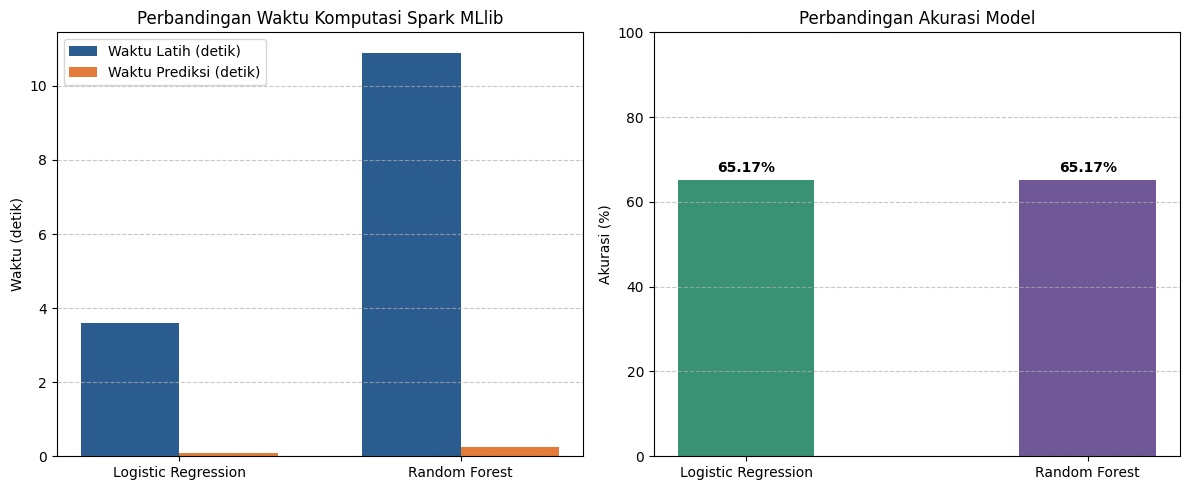

Grafik berhasil dibuat dan disimpan!


In [16]:
import matplotlib.pyplot as plt

# Data hasil eksperimen
models = ['Logistic Regression', 'Random Forest']
train_times = [lr_train_time, rf_train_time]
test_times = [lr_pred_time, rf_pred_time]
accuracies = [lr_accuracy * 100, rf_accuracy * 100]

# Buat canvas grafik dengan 2 kolom subplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
x = range(len(models))
width = 0.35

# Subplot 1: Perbandingan Waktu Komputasi
ax1 . bar([i - width/2 for i in x], train_times, width=width, label='Waktu Latih (detik)', color='#2b5c8f')
ax1 . bar([i + width/2 for i in x], test_times, width=width, label='Waktu Prediksi (detik)', color='#e27c38')
ax1.set_title('Perbandingan Waktu Komputasi Spark MLlib')
ax1.set_ylabel('Waktu (detik)')
ax1.set_xticks(list(x))
ax1.set_xticklabels(models)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Subplot 2: Perbandingan Akurasi Model
ax2 . bar(models, accuracies, color=['#3a9274', '#705898'], width=0.4)
ax2.set_title('Perbandingan Akurasi Model')
ax2.set_ylabel('Akurasi (%)')
ax2.set_ylim(0, 100)
for i, v in enumerate(accuracies):
    ax2.text(i, v + 2, f"{v:.2f}%", ha='center', fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

# Simpan grafik ke file gambar dan tampilkan di layar
plt.savefig("grafik_perbandingan_model.png", dpi=300)
plt . show()

print("Grafik berhasil dibuat dan disimpan!")